# 1. Import thư viện

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Hiển thị đầy đủ các cột
pd.set_option('display.max_columns', None)

# Style cho biểu đồ
sns.set_theme(style="whitegrid")

# 2. Đọc dữ liệu

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# 3. EDA và kiểm tra chất lượng dữ liệu

## 3.1. kiểm tra datatype và data shape

In [3]:
print(df.shape)

(45211, 17)


In [4]:
print(df.dtypes)

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object


## 3.2. Kiểm tra missing value

In [5]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': df.isnull().mean() * 100
})

missing = missing.sort_values(
    by='Missing Count',
    ascending=False
)

missing

,Missing Count,Missing Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
balance,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
day,0,0.0


ko có missing value 

## 3.3. Kiểm tra duplicate

In [6]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


ko có duplicate

## 3.4. Kiểm tra target y

In [7]:
print("đếm số lượng các giá trị của biến mục tiêu 'y':")
print(df['y'].value_counts())

target_distribution = df['y'].value_counts(normalize=True) * 100
print("\nPhân phối của biến mục tiêu 'y' (%):")
print(target_distribution)

target_table = pd.DataFrame({
    'Count': df['y'].value_counts(),
    'Percentage': df['y'].value_counts(normalize=True) * 100
})

target_table

đếm số lượng các giá trị của biến mục tiêu 'y':
y
no     39922
yes     5289
Name: count, dtype: int64

Phân phối của biến mục tiêu 'y' (%):
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


,Count,Percentage
y,,
no,39922,88.30152
yes,5289,11.69848


## 3.5. vẽ 4 biểu đồ 

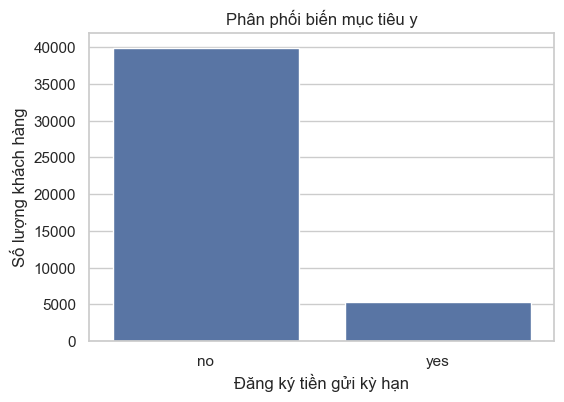

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='y')

plt.title('Phân phối biến mục tiêu y')
plt.xlabel('Đăng ký tiền gửi kỳ hạn')
plt.ylabel('Số lượng khách hàng')

plt.show()

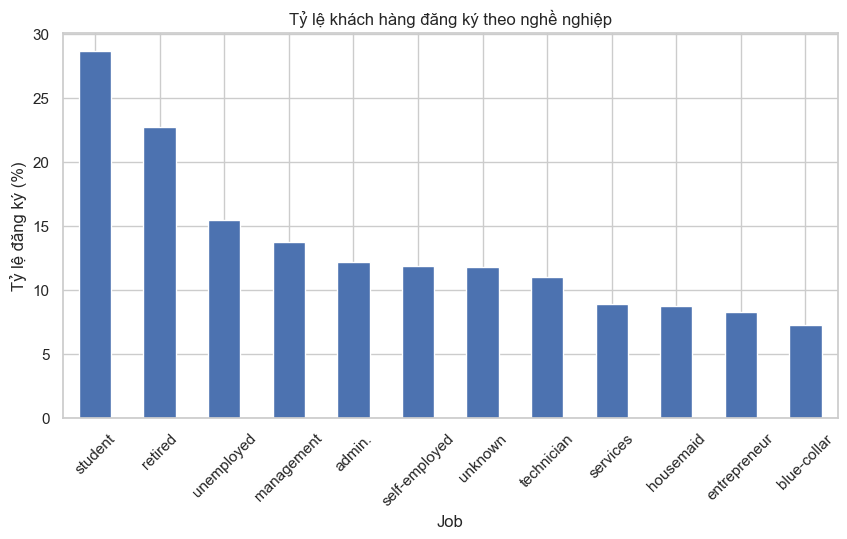

In [9]:
job_conversion = (
    df.groupby('job')['y']
      .apply(lambda x: (x == 'yes').mean() * 100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

job_conversion.plot(kind='bar')

plt.title('Tỷ lệ khách hàng đăng ký theo nghề nghiệp')
plt.xlabel('Job')
plt.ylabel('Tỷ lệ đăng ký (%)')
plt.xticks(rotation=45)

plt.show()

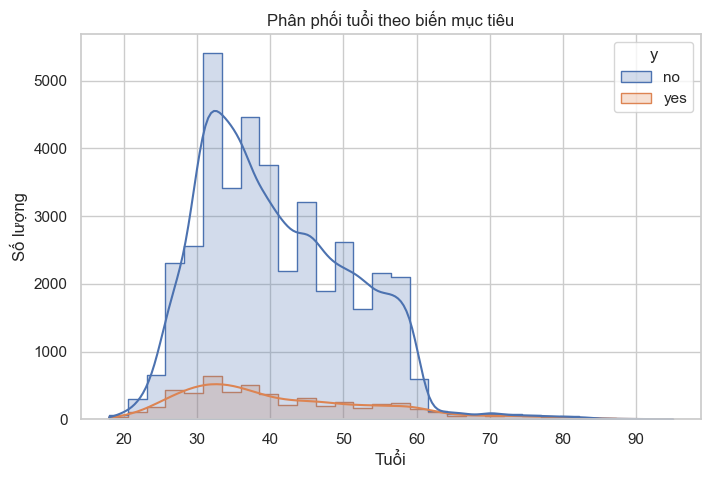

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='age',
    hue='y',
    bins=30,
    kde=True,
    element='step'
)

plt.title('Phân phối tuổi theo biến mục tiêu')
plt.xlabel('Tuổi')
plt.ylabel('Số lượng')

plt.show()

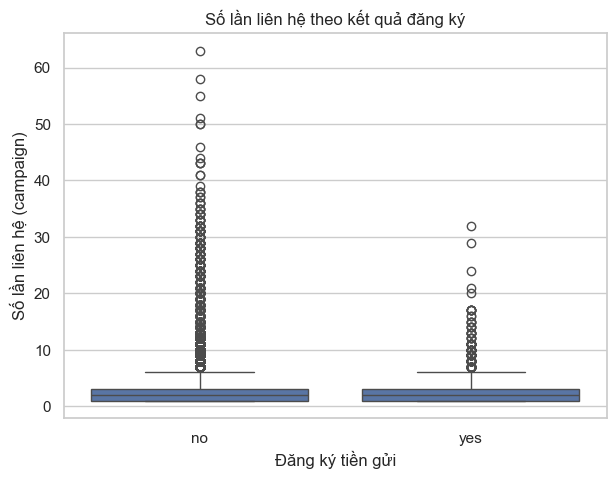

In [11]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='y',
    y='campaign'
)

plt.title('Số lần liên hệ theo kết quả đăng ký')
plt.xlabel('Đăng ký tiền gửi')
plt.ylabel('Số lần liên hệ (campaign)')

plt.show()

### Nhận xét EDA

* Biến mục tiêu `y` gồm hai lớp `no` và `yes`, trong đó số lượng khách hàng đăng ký tiền gửi (`yes`) thấp hơn đáng kể so với nhóm không đăng ký (`no`). Điều này cho thấy dữ liệu có hiện tượng **mất cân bằng lớp (class imbalance)**. Vì vậy, khi xây dựng mô hình cần quan tâm đến **precision, recall, F1-score và ROC-AUC**, thay vì chỉ sử dụng accuracy.

* Các biến categorical như `job`, `marital`, `education`, `contact` và `poutcome` có nhiều nhóm giá trị khác nhau. Do đó, các biến này cần được mã hóa trước khi đưa vào các mô hình Machine Learning, phù hợp với việc sử dụng **One-Hot Encoding** trong pipeline preprocessing.

* Biến `age` có sự phân bố không đồng đều giữa các nhóm tuổi. Khả năng đăng ký tiền gửi cũng có sự khác biệt giữa các nhóm tuổi, vì vậy biến tuổi có thể cung cấp thông tin hữu ích cho mô hình. Đây cũng là cơ sở để tạo thêm biến `age_group`.

* Biến `campaign` thể hiện số lần khách hàng được liên hệ trong chiến dịch hiện tại. Phân phối của biến này có sự chênh lệch và xuất hiện các giá trị lớn, do đó có thể tạo thêm biến `campaign_intensity` để biểu diễn mức độ liên hệ.

* Biến `previous` cho biết số lần khách hàng được liên hệ trong các chiến dịch trước. Phần lớn khách hàng có số lần liên hệ trước bằng 0, vì vậy việc tạo biến `previously_contacted` có thể giúp mô hình phân biệt khách hàng đã từng được tiếp cận với khách hàng chưa từng được tiếp cận.

* Biến `balance` có cả giá trị âm và dương và có thể có độ phân tán lớn. Vì vậy, việc tạo biến `balance_sign` giúp bổ sung thông tin về trạng thái số dư âm hoặc dương.

### Định hướng modeling

Từ kết quả EDA, có ba vấn đề chính cần được xử lý trong quá trình xây dựng mô hình: **biến categorical cần được mã hóa, các biến số cần được chuẩn hóa và dữ liệu bị mất cân bằng giữa hai lớp mục tiêu**. Do đó, bài toán sẽ sử dụng preprocessing pipeline, đồng thời thử nghiệm các phương pháp xử lý imbalance như `class_weight` và **SMOTE**.


# 4. Tạo ít nhất 3 feature mới 

In [12]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=['<=25', '26-35', '36-45', '46-55', '56-65', '>65']
)

In [13]:
df['previously_contacted'] = np.where(
    df['previous'] > 0,
    'yes',
    'no'
)

In [14]:
df['balance_sign'] = np.where(
    df['balance'] >= 0,
    'positive',
    'negative'
)

In [15]:
df['campaign_intensity'] = pd.cut(
    df['campaign'],
    bins=[0, 1, 2, 4, np.inf],
    labels=['Low', 'Medium', 'High', 'Very High']
)

In [16]:
df['previous_contact_group'] = pd.cut(
    df['previous'],
    bins=[-1, 0, 2, 5, np.inf],
    labels=['None', 'Few', 'Several', 'Many']
)

In [17]:
new_features = [
    'age_group',
    'previously_contacted',
    'balance_sign',
    'campaign_intensity',
    'previous_contact_group'
]

df[new_features].head(10)

,age_group,previously_contacted,balance_sign,campaign_intensity,previous_contact_group
0,56-65,no,positive,Low,None
1,36-45,no,positive,Low,None
2,26-35,no,positive,Low,None
3,46-55,no,positive,Low,None
4,26-35,no,positive,Low,None
5,26-35,no,positive,Low,None
6,26-35,no,positive,Low,None
7,36-45,no,positive,Low,None
8,56-65,no,positive,Low,None
9,36-45,no,positive,Low,None


# 5. Chia train/test

## 5.1. Tách biến đầu vào X và target y

In [18]:
X = df.drop(columns=['y'])
y = df['y'].map({'no': 0, 'yes': 1})

## 5.2. Chia Train/Test

In [19]:
from sklearn.model_selection import train_test_split
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (36168, 21)
X_test : (9043, 21)
y_train: (36168,)
y_test : (9043,)


## 5.3. Xác định biến số và biến categorical

In [20]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'age_group', 'previously_contacted', 'balance_sign', 'campaign_intensity', 'previous_contact_group']


## 5.4. Tạo Pipeline cho biến số và biến categorical

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer


numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [22]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

## 5.5. Kết hợp thành preprocessor

In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 6. Train tối thiểu năm model: Dummy Classifier, Logistic Regression, Decision Tree, Random Forest, Gradient Boosting

## 6.1. khai báo thư viện 

In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

## 6.2. khái báo 5 model

In [25]:
models = {
    'Dummy Classifier': DummyClassifier(
        strategy='most_frequent'
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

## 6.3. Tạo Pipeline cho từng model

In [26]:
model_pipelines = {}

for name, model in models.items():
    model_pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

## 6.4. Train và đánh giá 5 model

In [27]:
results = []

for name, pipeline in model_pipelines.items():

    print(f"\n{'='*60}")
    print(name)
    print('='*60)

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Probability
    if hasattr(pipeline, 'predict_proba'):
        y_prob = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_prob = None

    # Metrics
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    results.append({
        'Model': name,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'ROC-AUC': roc_auc
    })


Dummy Classifier
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000
ROC-AUC   : 0.5000

Confusion Matrix:
[[7985    0]
 [1058    0]]

Logistic Regression
Precision : 0.6480
Recall    : 0.3497
F1-score  : 0.4543
ROC-AUC   : 0.9074

Confusion Matrix:
[[7784  201]
 [ 688  370]]

Decision Tree
Precision : 0.4670
Recall    : 0.4811
F1-score  : 0.4739
ROC-AUC   : 0.7042

Confusion Matrix:
[[7404  581]
 [ 549  509]]

Random Forest
Precision : 0.6735
Recall    : 0.3743
F1-score  : 0.4812
ROC-AUC   : 0.9265

Confusion Matrix:
[[7793  192]
 [ 662  396]]

Gradient Boosting
Precision : 0.6517
Recall    : 0.4121
F1-score  : 0.5049
ROC-AUC   : 0.9234

Confusion Matrix:
[[7752  233]
 [ 622  436]]


In [28]:
results_df = pd.DataFrame(results)

results_df.sort_values(
    by='ROC-AUC',
    ascending=False
)

,Model,Precision,Recall,F1-score,ROC-AUC
3,Random Forest,0.673469,0.374291,0.481166,0.926528
4,Gradient Boosting,0.651719,0.412098,0.504922,0.923357
1,Logistic Regression,0.647986,0.349716,0.454266,0.907401
2,Decision Tree,0.466972,0.481096,0.473929,0.704167
0,Dummy Classifier,0.000000,0.000000,0.000000,0.500000


## 6.5. Vẽ Confusion Matrix cho 5 model

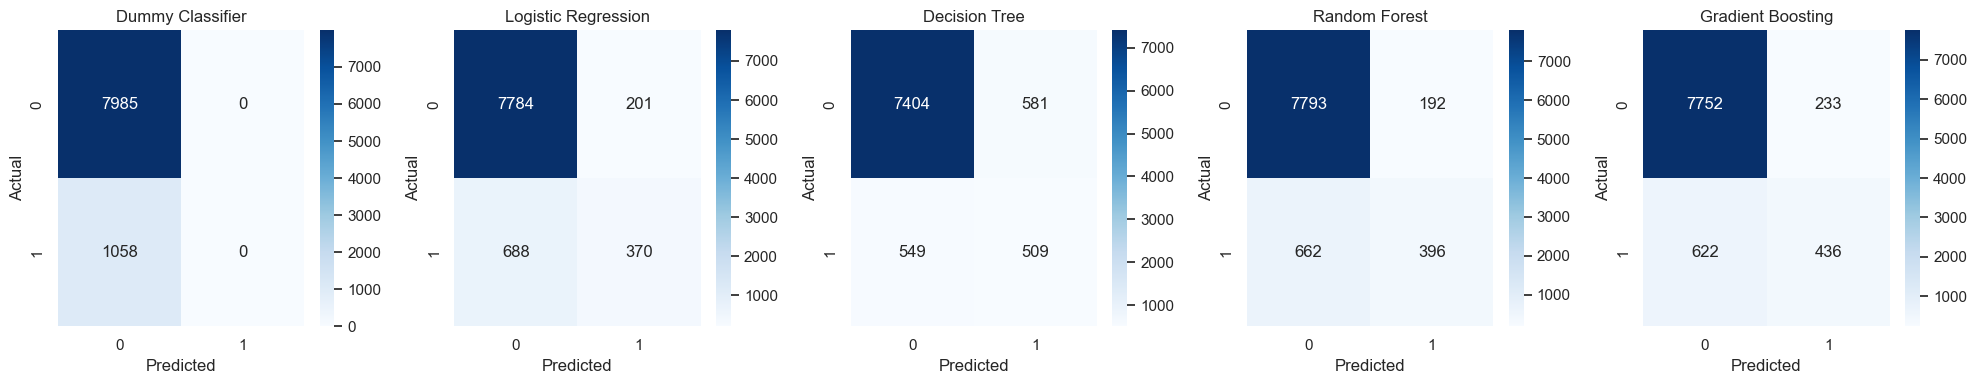

In [29]:
fig, axes = plt.subplots(
    1, 5,
    figsize=(20, 4)
)

for ax, (name, pipeline) in zip(
    axes,
    model_pipelines.items()
):
    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 6.6. Cross-validation cho positive class yes

In [30]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

for name, pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'CV Precision': scores['test_precision'].mean(),
        'CV Recall': scores['test_recall'].mean(),
        'CV F1': scores['test_f1'].mean(),
        'CV ROC-AUC': scores['test_roc_auc'].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.sort_values(
    by='CV ROC-AUC',
    ascending=False
)

,Model,CV Precision,CV Recall,CV F1,CV ROC-AUC
3,Random Forest,0.665899,0.359968,0.467186,0.926924
4,Gradient Boosting,0.664021,0.419287,0.513798,0.926254
1,Logistic Regression,0.646253,0.349806,0.453559,0.908996
2,Decision Tree,0.461272,0.470339,0.465722,0.698754
0,Dummy Classifier,0.000000,0.000000,0.000000,0.500000


### Nhận xét

Kết quả cho thấy **Random Forest** đạt ROC-AUC cao nhất trên tập test (0.9265) và Cross-Validation (0.9269), trong khi **Gradient Boosting** có Recall và F1-score cao hơn Random Forest. **Logistic Regression** cho kết quả ổn định giữa test và Cross-Validation, còn **Decision Tree** có hiệu quả thấp hơn hai mô hình ensemble. **Dummy Classifier** không nhận diện được lớp `yes` (Recall và F1-score bằng 0). Nhìn chung, các mô hình thực tế đều vượt Dummy Classifier và cần tiếp tục được thử nghiệm với các phương pháp xử lý mất cân bằng trước khi lựa chọn mô hình cuối cùng.


# 7 Thử ít nhất hai cách xử lý imbalance

## 7.1. Class Weight

In [31]:
class_weight_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=RANDOM_STATE
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=RANDOM_STATE
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

In [32]:
class_weight_pipelines = {}

for name, model in class_weight_models.items(): 
    class_weight_pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

## 7.2. SMOTE

In [33]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

In [34]:
smote_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

In [35]:
smote_pipelines = {}

for name, model in smote_models.items():
    smote_pipelines[name] = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', model)
    ])

## 7.3. Cross-validation với SMOTE

In [36]:
cv_smote_results = []

for name, pipeline in smote_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            'precision': 'precision',
            'recall': 'recall',
            'f1': 'f1',
            'roc_auc': 'roc_auc'
        },
        n_jobs=-1
    )

    cv_smote_results.append({
        'Model': name,
        'CV Precision (Yes)': scores['test_precision'].mean(),
        'CV Recall (Yes)': scores['test_recall'].mean(),
        'CV F1 (Yes)': scores['test_f1'].mean(),
        'CV ROC-AUC': scores['test_roc_auc'].mean()
    })

cv_smote_df = pd.DataFrame(cv_smote_results)

cv_smote_df

,Model,CV Precision (Yes),CV Recall (Yes),CV F1 (Yes),CV ROC-AUC
0,Logistic Regression,0.420657,0.801940,0.551824,0.909555
1,Decision Tree,0.458893,0.549047,0.499865,0.731611
2,Random Forest,0.587847,0.490904,0.534736,0.925932


## 7.4. Đánh giá Class Weight trên Test

In [37]:
class_weight_results = []

for name, pipeline in class_weight_pipelines.items():

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    class_weight_results.append({
        'Model': name,
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(
            y_test, y_prob
        )
    })

class_weight_df = pd.DataFrame(class_weight_results)

class_weight_df

,Model,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.417845,0.810019,0.551303,0.909178
1,Decision Tree,0.472277,0.450851,0.461315,0.692050
2,Random Forest,0.693654,0.299622,0.418482,0.927890


## 7.5. Đánh giá SMOTE trên Test

In [38]:
smote_results = []

for name, pipeline in smote_pipelines.items():

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    smote_results.append({
        'Model': name,
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(
            y_test, y_prob
        )
    })

smote_df = pd.DataFrame(smote_results)

smote_df

,Model,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.421578,0.797732,0.551634,0.907786
1,Decision Tree,0.455291,0.524575,0.487484,0.720709
2,Random Forest,0.607383,0.513233,0.556352,0.927244


## 7.6. Tạo bảng so sánh

In [39]:
class_weight_compare = class_weight_df.copy()
class_weight_compare['Method'] = 'Class Weight'

smote_compare = smote_df.copy()
smote_compare['Method'] = 'SMOTE'

imbalance_results = pd.concat(
    [class_weight_compare, smote_compare],
    ignore_index=True
)

imbalance_results = imbalance_results[
    ['Method', 'Model', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
]

imbalance_results

,Method,Model,Precision,Recall,F1-score,ROC-AUC
0,Class Weight,Logistic Regression,0.417845,0.810019,0.551303,0.909178
1,Class Weight,Decision Tree,0.472277,0.450851,0.461315,0.692050
2,Class Weight,Random Forest,0.693654,0.299622,0.418482,0.927890
3,SMOTE,Logistic Regression,0.421578,0.797732,0.551634,0.907786
4,SMOTE,Decision Tree,0.455291,0.524575,0.487484,0.720709
5,SMOTE,Random Forest,0.607383,0.513233,0.556352,0.927244


### Nhận xét

Hai phương pháp xử lý mất cân bằng gồm **Class Weight** và **SMOTE** cho kết quả khác nhau giữa các mô hình. Class Weight kết hợp với Logistic Regression cho Recall cao nhất là 0.8100, trong khi Class Weight kết hợp với Random Forest đạt ROC-AUC cao nhất là 0.9279. Với SMOTE, Random Forest đạt F1-score cao nhất trong nhóm này là 0.5564 và Recall tăng lên 0.5132.

Kết quả cho thấy việc xử lý mất cân bằng giúp thay đổi đáng kể sự cân bằng giữa Precision và Recall. Tuy nhiên, chưa thể chọn mô hình và threshold cuối cùng chỉ dựa trên các chỉ số trên, vì bài toán có chi phí bỏ sót khách hàng (FN) cao hơn chi phí gọi nhầm khách hàng (FP). Do đó, bước tiếp theo sẽ chọn threshold trên validation data dựa trên Total Cost = 4 × FN + FP, sau đó mới đánh giá mô hình một lần trên test set.


# 8. Chọn threshold theo chi phí nghiệp vụ

## 8.1. Chia Training thành Train và Validation

In [40]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Train:", X_train_sub.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (28934, 21)
Validation: (7234, 21)
Test: (9043, 21)


## 8.2. Tạo danh sách các model đã xử lý imbalance

In [41]:
candidate_pipelines = {}

candidate_pipelines.update(class_weight_pipelines)
candidate_pipelines.update({
    f'SMOTE - {name}': pipeline
    for name, pipeline in smote_pipelines.items()
})

print(candidate_pipelines.keys())

dict_keys(['Logistic Regression', 'Decision Tree', 'Random Forest', 'SMOTE - Logistic Regression', 'SMOTE - Decision Tree', 'SMOTE - Random Forest'])


## 8.3. Chọn các threshold cần thử

In [42]:
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

## 8.4. Tính FP, FN và Total Cost trên Validation

In [43]:
threshold_results = []

for name, pipeline in candidate_pipelines.items():

    # Train chỉ trên training subset
    pipeline.fit(X_train_sub, y_train_sub)

    # Xác suất trên validation
    y_val_prob = pipeline.predict_proba(X_val)[:, 1]

    for threshold in thresholds:

        # Chuyển probability thành prediction theo threshold
        y_val_pred = (y_val_prob >= threshold).astype(int)

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_val,
            y_val_pred,
            labels=[0, 1]
        ).ravel()

        # Chi phí nghiệp vụ
        total_cost = 4 * fn + fp

        threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'FP': fp,
            'FN': fn,
            'Total Cost': total_cost
        })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Model,Threshold,FP,FN,Total Cost
0,Logistic Regression,0.1,4059,4,4075
1,Logistic Regression,0.2,2543,21,2627
2,Logistic Regression,0.3,1743,45,1923
3,Logistic Regression,0.4,1290,92,1658
4,Logistic Regression,0.5,953,153,1565
5,Logistic Regression,0.6,725,204,1541
6,Decision Tree,0.1,464,460,2304
7,Decision Tree,0.2,464,460,2304
8,Decision Tree,0.3,464,460,2304
9,Decision Tree,0.4,464,460,2304


## 8.5. Tìm threshold có chi phí thấp nhất trên Validation

In [44]:
best_validation_result = threshold_df.loc[
    threshold_df['Total Cost'].idxmin()
]

best_validation_result

Model         Random Forest
Threshold               0.2
FP                      800
FN                      121
Total Cost             1284
Name: 13, dtype: object

## 8.6. Xem kết quả theo từng model

In [45]:
threshold_df.sort_values(
    ['Model', 'Total Cost']
)

,Model,Threshold,FP,FN,Total Cost
6,Decision Tree,0.1,464,460,2304
7,Decision Tree,0.2,464,460,2304
8,Decision Tree,0.3,464,460,2304
9,Decision Tree,0.4,464,460,2304
10,Decision Tree,0.5,464,460,2304
11,Decision Tree,0.6,464,460,2304
5,Logistic Regression,0.6,725,204,1541
4,Logistic Regression,0.5,953,153,1565
3,Logistic Regression,0.4,1290,92,1658
2,Logistic Regression,0.3,1743,45,1923


## 8.7. Lấy model và threshold cuối cùng

In [46]:
best_model_name = best_validation_result['Model']
best_threshold = best_validation_result['Threshold']

print("Model được chọn:", best_model_name)
print("Threshold được chọn:", best_threshold)
print("Validation Total Cost:", best_validation_result['Total Cost'])

Model được chọn: Random Forest
Threshold được chọn: 0.2
Validation Total Cost: 1284


## 8.8 Train lại model trên toàn bộ Training data

In [47]:
final_pipeline = candidate_pipelines[best_model_name]

final_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 8.9. Đánh giá đúng một lần trên Test

In [48]:
y_test_prob = final_pipeline.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
).ravel()

test_cost = 4 * fn + fp

print("=== FINAL TEST RESULT ===")
print("Model:", best_model_name)
print("Threshold:", best_threshold)
print("FP:", fp)
print("FN:", fn)
print("Total Cost:", test_cost)

print("Precision:",
      precision_score(y_test, y_test_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_test_pred, zero_division=0))

print("F1-score:",
      f1_score(y_test, y_test_pred, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_prob))

=== FINAL TEST RESULT ===
Model: Random Forest
Threshold: 0.2
FP: 993
FN: 195
Total Cost: 1773
Precision: 0.46497844827586204
Recall: 0.8156899810964083
F1-score: 0.5923129718599863
ROC-AUC: 0.9278901958184829


In [49]:
# Dự đoán trên tập test bằng model cuối cùng
y_test_prob = final_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= best_threshold).astype(int)

# Tạo bảng predictions
predictions_df = X_test.copy()

predictions_df["actual"] = y_test.to_numpy()
predictions_df["probability"] = y_test_prob
predictions_df["prediction"] = y_test_pred
predictions_df["threshold"] = best_threshold

# Lưu file
predictions_df.to_csv("predictions.csv", index=False)

print("Đã tạo predictions.csv")
print("Số dòng:", len(predictions_df))
display(predictions_df.head())

Đã tạo predictions.csv
Số dòng: 9043


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,age_group,previously_contacted,balance_sign,campaign_intensity,previous_contact_group,actual,probability,prediction,threshold
1392,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,347,2,-1,0,unknown,36-45,no,positive,Medium,None,0,0.005,0,0.2
7518,44,technician,married,secondary,no,378,yes,no,unknown,30,may,203,2,-1,0,unknown,36-45,no,positive,Medium,None,0,0.000,0,0.2
12007,31,services,married,secondary,no,356,yes,no,unknown,20,jun,228,5,-1,0,unknown,26-35,no,positive,Very High,None,0,0.005,0,0.2
5536,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,153,4,-1,0,unknown,36-45,no,positive,High,None,0,0.000,0,0.2
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,61,1,-1,0,unknown,26-35,no,positive,Low,None,0,0.030,0,0.2


### Nhận xét lựa chọn threshold

Threshold được lựa chọn dựa trên validation data theo hàm chi phí nghiệp vụ, trong đó FN có chi phí 4 đơn vị và FP có chi phí 1 đơn vị. Sau khi thử các threshold từ 0.10 đến 0.60, mô hình Random Forest với threshold 0.20 được lựa chọn.

Khi đánh giá một lần trên tập test, mô hình đạt Recall 0.8157, Precision 0.4650, F1-score 0.5923 và ROC-AUC 0.9279. Mô hình tạo ra 993 trường hợp FP và 195 trường hợp FN. Tổng chi phí nghiệp vụ là:

**Total Cost = 4 × 195 + 993 = 1,773.**

Threshold 0.20 giúp mô hình ưu tiên giảm số khách hàng thực sự đăng ký nhưng bị bỏ sót, phù hợp với giả định rằng chi phí của FN cao hơn FP.


# 9. Giải thích Random Forest

## 9.1. Lấy feature importance

In [50]:
# Lấy preprocessor và model từ final pipeline
final_preprocessor = final_pipeline.named_steps['preprocessor']
final_model = final_pipeline.named_steps['model']

# Tên các feature sau preprocessing
feature_names = final_preprocessor.get_feature_names_out()

# Feature importance của Random Forest
importances = final_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feature_importance_df = feature_importance_df.sort_values(
    'Importance',
    ascending=False
)

feature_importance_df.head(10)

,Feature,Importance
3,num__duration,0.324051
1,num__balance,0.068178
2,num__day,0.060702
0,num__age,0.059097
49,cat__poutcome_success,0.026805
34,cat__contact_unknown,0.026372
5,num__pdays,0.024665
4,num__campaign,0.021609
29,cat__housing_yes,0.017714
28,cat__housing_no,0.016211


## 9.2. Gộp các feature One-Hot về feature gốc

In [51]:
def get_original_feature(transformed_feature):
    feature = transformed_feature.split('__', 1)[-1]

    # Numerical feature
    if transformed_feature.startswith('num__'):
        return feature

    # Categorical feature
    if transformed_feature.startswith('cat__'):
        for col in categorical_features:
            if feature == col or feature.startswith(col + '_'):
                return col

    return feature


feature_importance_df['Original Feature'] = (
    feature_importance_df['Feature']
    .apply(get_original_feature)
)

grouped_importance_df = (
    feature_importance_df
    .groupby('Original Feature', as_index=False)['Importance']
    .sum()
    .sort_values('Importance', ascending=False)
)

grouped_importance_df.head(10)

,Original Feature,Importance
9,duration,0.324051
15,month,0.100076
2,balance,0.068178
7,day,0.060702
0,age,0.059097
12,job,0.055507
6,contact,0.044139
17,poutcome,0.041594
11,housing,0.033924
1,age_group,0.033217


## 9.3. Vẽ 10 feature quan trọng nhất

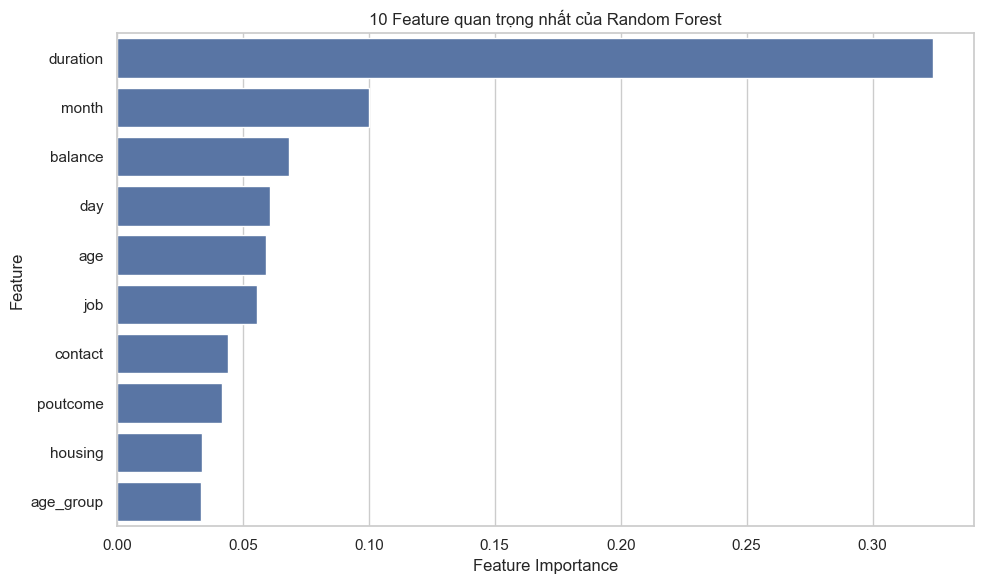

In [52]:
top_features = grouped_importance_df.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Original Feature'
)

plt.title('10 Feature quan trọng nhất của Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

## 9.4. Lấy khách hàng có xác suất đăng ký cao và thấp

In [53]:
test_prob = final_pipeline.predict_proba(X_test)[:, 1]

customer_analysis = X_test.copy()

customer_analysis['actual_y'] = y_test.values
customer_analysis['probability'] = test_prob
customer_analysis['prediction'] = (
    test_prob >= best_threshold
).astype(int)

In [54]:
high_probability_customer = customer_analysis.loc[
    customer_analysis['probability'].idxmax()
]

high_probability_customer

age                              25
job                         student
marital                      single
education                 secondary
default                          no
balance                         469
housing                          no
loan                             no
contact                    cellular
day                              24
month                           feb
duration                        524
campaign                          1
pdays                           187
previous                          2
poutcome                    success
age_group                      <=25
previously_contacted            yes
balance_sign               positive
campaign_intensity              Low
previous_contact_group          Few
actual_y                          0
probability                   0.935
prediction                        1
Name: 43135, dtype: object

In [55]:
low_probability_customer = customer_analysis.loc[
    customer_analysis['probability'].idxmin()
]

low_probability_customer

age                               44
job                       technician
marital                      married
education                  secondary
default                           no
balance                          378
housing                          yes
loan                              no
contact                      unknown
day                               30
month                            may
duration                         203
campaign                           2
pdays                             -1
previous                           0
poutcome                     unknown
age_group                      36-45
previously_contacted              no
balance_sign                positive
campaign_intensity            Medium
previous_contact_group          None
actual_y                           0
probability                      0.0
prediction                         0
Name: 7518, dtype: object

In [56]:
print("===== KHÁCH HÀNG XÁC SUẤT CAO =====")
print(high_probability_customer)

print("\n===== KHÁCH HÀNG XÁC SUẤT THẤP =====")
print(low_probability_customer)

===== KHÁCH HÀNG XÁC SUẤT CAO =====
age                              25
job                         student
marital                      single
education                 secondary
default                          no
balance                         469
housing                          no
loan                             no
contact                    cellular
day                              24
month                           feb
duration                        524
campaign                          1
pdays                           187
previous                          2
poutcome                    success
age_group                      <=25
previously_contacted            yes
balance_sign               positive
campaign_intensity              Low
previous_contact_group          Few
actual_y                          0
probability                   0.935
prediction                        1
Name: 43135, dtype: object

===== KHÁCH HÀNG XÁC SUẤT THẤP =====
age                               4

# 10. Fairness Audit

## 10.1 Lấy prediction trên test

In [57]:
audit_df = X_test.copy()

audit_df['actual'] = y_test.values
audit_df['probability'] = final_pipeline.predict_proba(X_test)[:, 1]

audit_df['prediction'] = (
    audit_df['probability'] >= best_threshold
).astype(int)

## 10.2. Tạo hàm tính Fairness Metrics

In [58]:
def fairness_metrics(data, group_column):

    results = []

    for group, group_data in data.groupby(group_column, observed=False):

        actual = group_data['actual']
        prediction = group_data['prediction']

        tn, fp, fn, tp = confusion_matrix(
            actual,
            prediction,
            labels=[0, 1]
        ).ravel()

        positive_rate = prediction.mean()

        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0

        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        results.append({
            'Group': group,
            'Prediction Positive Rate': positive_rate,
            'Recall / TPR': tpr,
            'False Positive Rate': fpr,
            'Count': len(group_data)
        })

    return pd.DataFrame(results)

## 10.3. Fairness audit theo tuổi

In [59]:
age_fairness = fairness_metrics(
    audit_df,
    'age_group'
)

age_fairness

,Group,Prediction Positive Rate,Recall / TPR,False Positive Rate,Count
0,<=25,0.396887,0.877193,0.260000,257
1,26-35,0.216013,0.792553,0.135246,3060
2,36-45,0.166425,0.821138,0.102309,2758
3,46-55,0.165901,0.796954,0.095346,1959
4,56-65,0.222607,0.803279,0.127517,867
5,>65,0.816901,0.966667,0.707317,142


## 10.4. Fairness audit theo job

In [60]:
job_fairness = fairness_metrics(
    audit_df,
    'job'
)

job_fairness

,Group,Prediction Positive Rate,Recall / TPR,False Positive Rate,Count
0,admin.,0.194175,0.786885,0.114537,1030
1,blue-collar,0.129338,0.788321,0.078187,1902
2,entrepreneur,0.149502,0.727273,0.103943,301
3,housemaid,0.158590,0.833333,0.078818,227
4,management,0.237288,0.803846,0.149970,1947
5,retired,0.413717,0.910000,0.272727,452
6,self-employed,0.208333,0.822222,0.113402,336
7,services,0.150124,0.774648,0.089796,806
8,student,0.511111,0.920000,0.353846,180
9,technician,0.202747,0.813559,0.122781,1529


In [61]:
print("===== FAIRNESS AUDIT: AGE GROUP =====")
display(age_fairness)

print("===== FAIRNESS AUDIT: JOB =====")
display(job_fairness)

===== FAIRNESS AUDIT: AGE GROUP =====


,Group,Prediction Positive Rate,Recall / TPR,False Positive Rate,Count
0,<=25,0.396887,0.877193,0.260000,257
1,26-35,0.216013,0.792553,0.135246,3060
2,36-45,0.166425,0.821138,0.102309,2758
3,46-55,0.165901,0.796954,0.095346,1959
4,56-65,0.222607,0.803279,0.127517,867
5,>65,0.816901,0.966667,0.707317,142


===== FAIRNESS AUDIT: JOB =====


,Group,Prediction Positive Rate,Recall / TPR,False Positive Rate,Count
0,admin.,0.194175,0.786885,0.114537,1030
1,blue-collar,0.129338,0.788321,0.078187,1902
2,entrepreneur,0.149502,0.727273,0.103943,301
3,housemaid,0.158590,0.833333,0.078818,227
4,management,0.237288,0.803846,0.149970,1947
5,retired,0.413717,0.910000,0.272727,452
6,self-employed,0.208333,0.822222,0.113402,336
7,services,0.150124,0.774648,0.089796,806
8,student,0.511111,0.920000,0.353846,180
9,technician,0.202747,0.813559,0.122781,1529


### Giải thích Model

Mô hình cuối cùng là Random Forest với threshold 0.20. Feature importance được sử dụng để giải thích mức độ quan trọng của các biến trong mô hình. Năm feature quan trọng nhất gồm `duration` (0.324051), `month` (0.100076), `balance` (0.068178), `day` (0.060702) và `age` (0.059097). Trong đó, `duration` có mức importance cao nhất. Các giá trị này thể hiện mức độ quan trọng tương đối của feature trong Random Forest và không trực tiếp cho biết chiều tác động làm tăng hay giảm xác suất đăng ký.

Một khách hàng có xác suất đăng ký cao có mã dòng 43135, với xác suất dự đoán 0.935. Hồ sơ này có tuổi 25, nghề nghiệp `student`, balance 469, contact `cellular`, duration 524, campaign 1, previous 2 và `poutcome = success`. Vì xác suất 0.935 lớn hơn threshold 0.20, model dự đoán khách hàng sẽ đăng ký. Tuy nhiên, giá trị thực tế là `No`, do đó trường hợp này là False Positive.

Một khách hàng có xác suất đăng ký thấp có mã dòng 7518, với xác suất dự đoán 0.0. Hồ sơ này có tuổi 44, nghề nghiệp `technician`, balance 378, housing `yes`, contact `unknown`, duration 203, campaign 2, previous 0 và `poutcome = unknown`. Model dự đoán `No` và giá trị thực tế cũng là `No`, nên đây là True Negative.

### Fairness Audit

Fairness audit được thực hiện trên tập test theo hai nhóm là `age_group` và `job`, sử dụng ba chỉ số Prediction Positive Rate, Recall/TPR và False Positive Rate.

Theo nhóm tuổi, các chỉ số có sự khác biệt giữa các nhóm. Nhóm `>65` có Prediction Positive Rate 81.69%, Recall 96.67% và False Positive Rate 70.73%, trong khi nhóm `46-55` có các giá trị tương ứng là 16.59%, 79.70% và 9.53%. Nhóm `>65` chỉ có 142 mẫu nên các tỷ lệ của nhóm này cần được diễn giải thận trọng.

Theo nghề nghiệp, cũng quan sát thấy sự khác biệt giữa các nhóm. Ví dụ, nhóm `student` có Prediction Positive Rate 51.11%, Recall 92.00% và False Positive Rate 35.38%, trong khi nhóm `blue-collar` có các giá trị tương ứng là 12.93%, 78.83% và 7.82%. Nhóm `student` có 180 mẫu, do đó kích thước nhóm cũng cần được xem xét khi diễn giải kết quả.

Fairness audit cho thấy hiệu suất và tỷ lệ dự đoán positive của mô hình không đồng nhất giữa các nhóm tuổi và nghề nghiệp. Các kết quả này được báo cáo để đánh giá sự khác biệt trong hành vi dự đoán của mô hình giữa các nhóm.


# 11. Lưu final_pipeline thành bank_marketing_pipeline.pkl.

In [62]:
import joblib

joblib.dump(
    final_pipeline,
    'bank_marketing_pipeline.pkl'
)

print("Đã lưu bank_marketing_pipeline.pkl")

Đã lưu bank_marketing_pipeline.pkl


# 12. Tạo requirements.txt

In [63]:
requirements = """Flask
pandas
numpy
scikit-learn==1.7.2
imbalanced-learn
joblib
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

print("Đã tạo requirements.txt")

Đã tạo requirements.txt


# 13. Tạo model_card.md

In [64]:
model_card = """# Model Card – Bank Marketing Classification

## 1. Tổng quan

- Bài toán: Dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không.
- Dataset: UCI Bank Marketing Dataset.
- Số dòng: 45,211.
- Số feature gốc: 16.
- Target: `y`.
- Train/Test: 80/20, stratified.
- Model cuối cùng: Random Forest.
- Model version: `bank-marketing-rf-v1.0`.

## 2. Feature Engineering

Đã tạo 5 feature mới:

- `age_group`
- `previously_contacted`
- `balance_sign`
- `campaign_intensity`
- `previous_contact_group`

Các feature được tạo trước khi chia train/test nhưng không sử dụng target để tạo feature.

## 3. Preprocessing

### Numerical features

- SimpleImputer với median.
- StandardScaler.

### Categorical features

- SimpleImputer với most_frequent.
- OneHotEncoder với `handle_unknown='ignore'`.

Preprocessing được đặt trong Pipeline nên scaler và encoder chỉ được fit trên dữ liệu training.

## 4. Xử lý mất cân bằng

Đã thử hai phương pháp:

1. Class Weight với `class_weight='balanced'`.
2. SMOTE.

SMOTE được đặt bên trong pipeline để chỉ resample dữ liệu training.

## 5. Các model đã thử

- Dummy Classifier
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting

Ngoài ra đã thử các model với class weight và SMOTE.

## 6. Model cuối cùng

- Model: Random Forest
- Phương pháp imbalance: Class Weight
- Threshold: 0.20
- Model version: `bank-marketing-rf-v1.0`

Threshold được lựa chọn trên validation data dựa trên chi phí nghiệp vụ.

## 7. Business Cost

Giả sử:

- False Negative (FN): chi phí 4.
- False Positive (FP): chi phí 1.

Công thức:

`Total Cost = 4 × FN + FP`

Threshold cuối cùng:

`0.20`

## 8. Kết quả trên Test Set

| Metric | Result |
|---|---:|
| Precision | 0.464978 |
| Recall | 0.815690 |
| F1-score | 0.592313 |
| ROC-AUC | 0.927890 |
| FP | 993 |
| FN | 195 |
| Total Cost | 1773 |
| Threshold | 0.20 |

Tính chi phí:

`4 × 195 + 993 = 1773`

## 9. Feature Importance

Top các feature quan trọng:

| Feature | Importance |
|---|---:|
| duration | 0.324051 |
| month | 0.100076 |
| balance | 0.068178 |
| day | 0.060702 |
| age | 0.059097 |
| job | 0.055507 |
| contact | 0.044139 |
| poutcome | 0.041594 |
| housing | 0.033924 |
| age_group | 0.033217 |

Feature importance thể hiện mức độ đóng góp tương đối của feature trong Random Forest, không thể hiện trực tiếp chiều tác động tăng hoặc giảm xác suất.

## 10. Ví dụ dự đoán

### Khách hàng có xác suất cao

- Age: 25
- Job: student
- Marital: single
- Education: secondary
- Balance: 469
- Housing: no
- Loan: no
- Contact: cellular
- Duration: 524
- Campaign: 1
- Pdays: 187
- Previous: 2
- Poutcome: success

Kết quả:

- Probability: 0.935
- Prediction: 1
- Opportunity level: High
- Actual: 0

Đây là một False Positive.

### Khách hàng có xác suất thấp

- Age: 44
- Job: technician
- Marital: married
- Education: secondary
- Balance: 378
- Housing: yes
- Loan: no
- Contact: unknown
- Duration: 203
- Campaign: 2
- Pdays: -1
- Previous: 0
- Poutcome: unknown

Kết quả:

- Probability: 0.0
- Prediction: 0
- Opportunity level: Low
- Actual: 0

Đây là một True Negative.

## 11. Fairness Audit

Audit được thực hiện theo nhóm tuổi và nhóm `job`.

Các chỉ số:

- Prediction Positive Rate
- Recall / TPR
- False Positive Rate

### Age Group

| Group | Positive Rate | Recall / TPR | FPR | Count |
|---|---:|---:|---:|---:|
| <=25 | 0.396887 | 0.877193 | 0.260000 | 257 |
| 26-35 | 0.216013 | 0.792553 | 0.135246 | 3060 |
| 36-45 | 0.166425 | 0.821138 | 0.102309 | 2758 |
| 46-55 | 0.165901 | 0.796954 | 0.095346 | 1959 |
| 56-65 | 0.222607 | 0.803279 | 0.127517 | 867 |
| >65 | 0.816901 | 0.966667 | 0.707317 | 142 |

### Job

| Job | Positive Rate | Recall / TPR | FPR | Count |
|---|---:|---:|---:|---:|
| admin. | 0.194175 | 0.786885 | 0.114537 | 1030 |
| blue-collar | 0.129338 | 0.788321 | 0.078187 | 1902 |
| entrepreneur | 0.149502 | 0.727273 | 0.103943 | 301 |
| housemaid | 0.158590 | 0.833333 | 0.078818 | 227 |
| management | 0.237288 | 0.803846 | 0.149970 | 1947 |
| retired | 0.413717 | 0.910000 | 0.272727 | 452 |
| self-employed | 0.208333 | 0.822222 | 0.113402 | 336 |
| services | 0.150124 | 0.774648 | 0.089796 | 806 |
| student | 0.511111 | 0.920000 | 0.353846 | 180 |
| technician | 0.202747 | 0.813559 | 0.122781 | 1529 |
| unemployed | 0.250896 | 0.795455 | 0.148936 | 279 |
| unknown | 0.314815 | 1.000000 | 0.229167 | 54 |

Có sự khác biệt về các chỉ số giữa các nhóm. Những nhóm có số lượng mẫu nhỏ cần được diễn giải thận trọng.

## 12. API

Endpoint:

`POST /predict`

API nhận 16 feature gốc dưới dạng JSON.

API tự tạo 5 feature engineering giống notebook trước khi đưa dữ liệu vào pipeline.

Response gồm:

- `prediction`
- `probability`
- `threshold`
- `model_version`
- `opportunity_level`

Model version:

`bank-marketing-rf-v1.0`

## 13. Limitations

- Dataset có class imbalance.
- Threshold 0.20 phụ thuộc vào giả định chi phí FN = 4 và FP = 1.
- Feature importance không cho biết trực tiếp chiều tác động.
- Một số nhóm fairness có số lượng mẫu nhỏ.
- Khi triển khai thực tế cần theo dõi data drift và hiệu năng mô hình theo thời gian.
"""

with open("model_card.md", "w", encoding="utf-8") as f:
    f.write(model_card)

print("Đã tạo model_card.md")

Đã tạo model_card.md
